# Análisis exploratorio

In [28]:
# Librerías PyData
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import sklearn

In [29]:
# Carga de datos: modificar estas variables si cambia la ubicación o el nombre de las fuentes
import os
from pathlib import Path

DATA_DIR = Path(os.getenv("RAW_DATA_DIR", "../data/raw"))
TRAIN_FILE = "train.csv"
TEST_FILE = "test.csv"

train = pd.read_csv(DATA_DIR / TRAIN_FILE)
test = pd.read_csv(DATA_DIR / TEST_FILE)

print(f"train: {train.shape}")
print(f"test: {test.shape}")

train: (1460, 81)
test: (1459, 80)


## Variable target: SalePrice

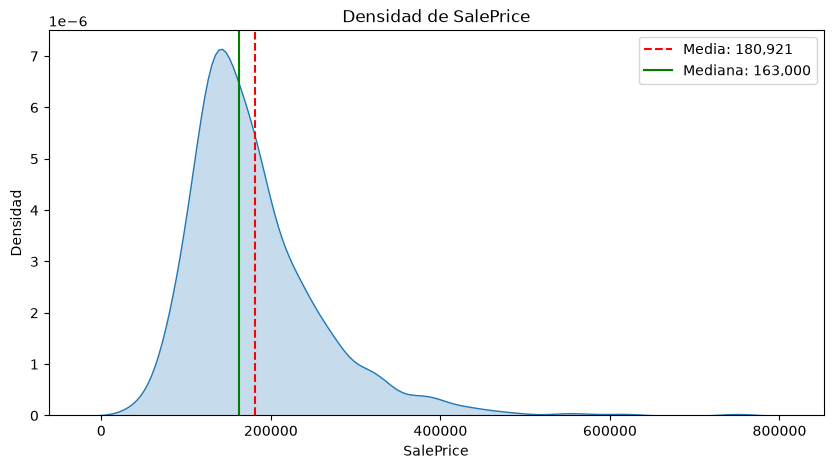

In [30]:
TARGET = "SalePrice"

media = train[TARGET].mean()
mediana = train[TARGET].median()

fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(data=train, x=TARGET, fill=True, ax=ax)
ax.axvline(media, color="red", linestyle="--", label=f"Media: {media:,.0f}")
ax.axvline(mediana, color="green", linestyle="-", label=f"Mediana: {mediana:,.0f}")
ax.set_title(f"Densidad de {TARGET}")
ax.set_xlabel(TARGET)
ax.set_ylabel("Densidad")
ax.legend()
plt.show()

## Relación de las variables numéricas con SalePrice

In [31]:
# Variables numéricas, excluyendo el identificador y la variable target
variables_numericas = [
    col for col in train.select_dtypes(include="number").columns if col not in ("Id", TARGET)
]

# Una variable se considera discreta si tiene pocos valores distintos
MAX_VALORES_DISCRETA = 15

discretas = [col for col in variables_numericas if train[col].nunique() <= MAX_VALORES_DISCRETA]
continuas = [col for col in variables_numericas if col not in discretas]

print(f"discretas ({len(discretas)}): {discretas}")
print(f"continuas ({len(continuas)}): {continuas}")

discretas (15): ['MSSubClass', 'OverallQual', 'OverallCond', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageCars', 'PoolArea', 'MoSold', 'YrSold']
continuas (21): ['LotFrontage', 'LotArea', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'GarageYrBlt', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'MiscVal']


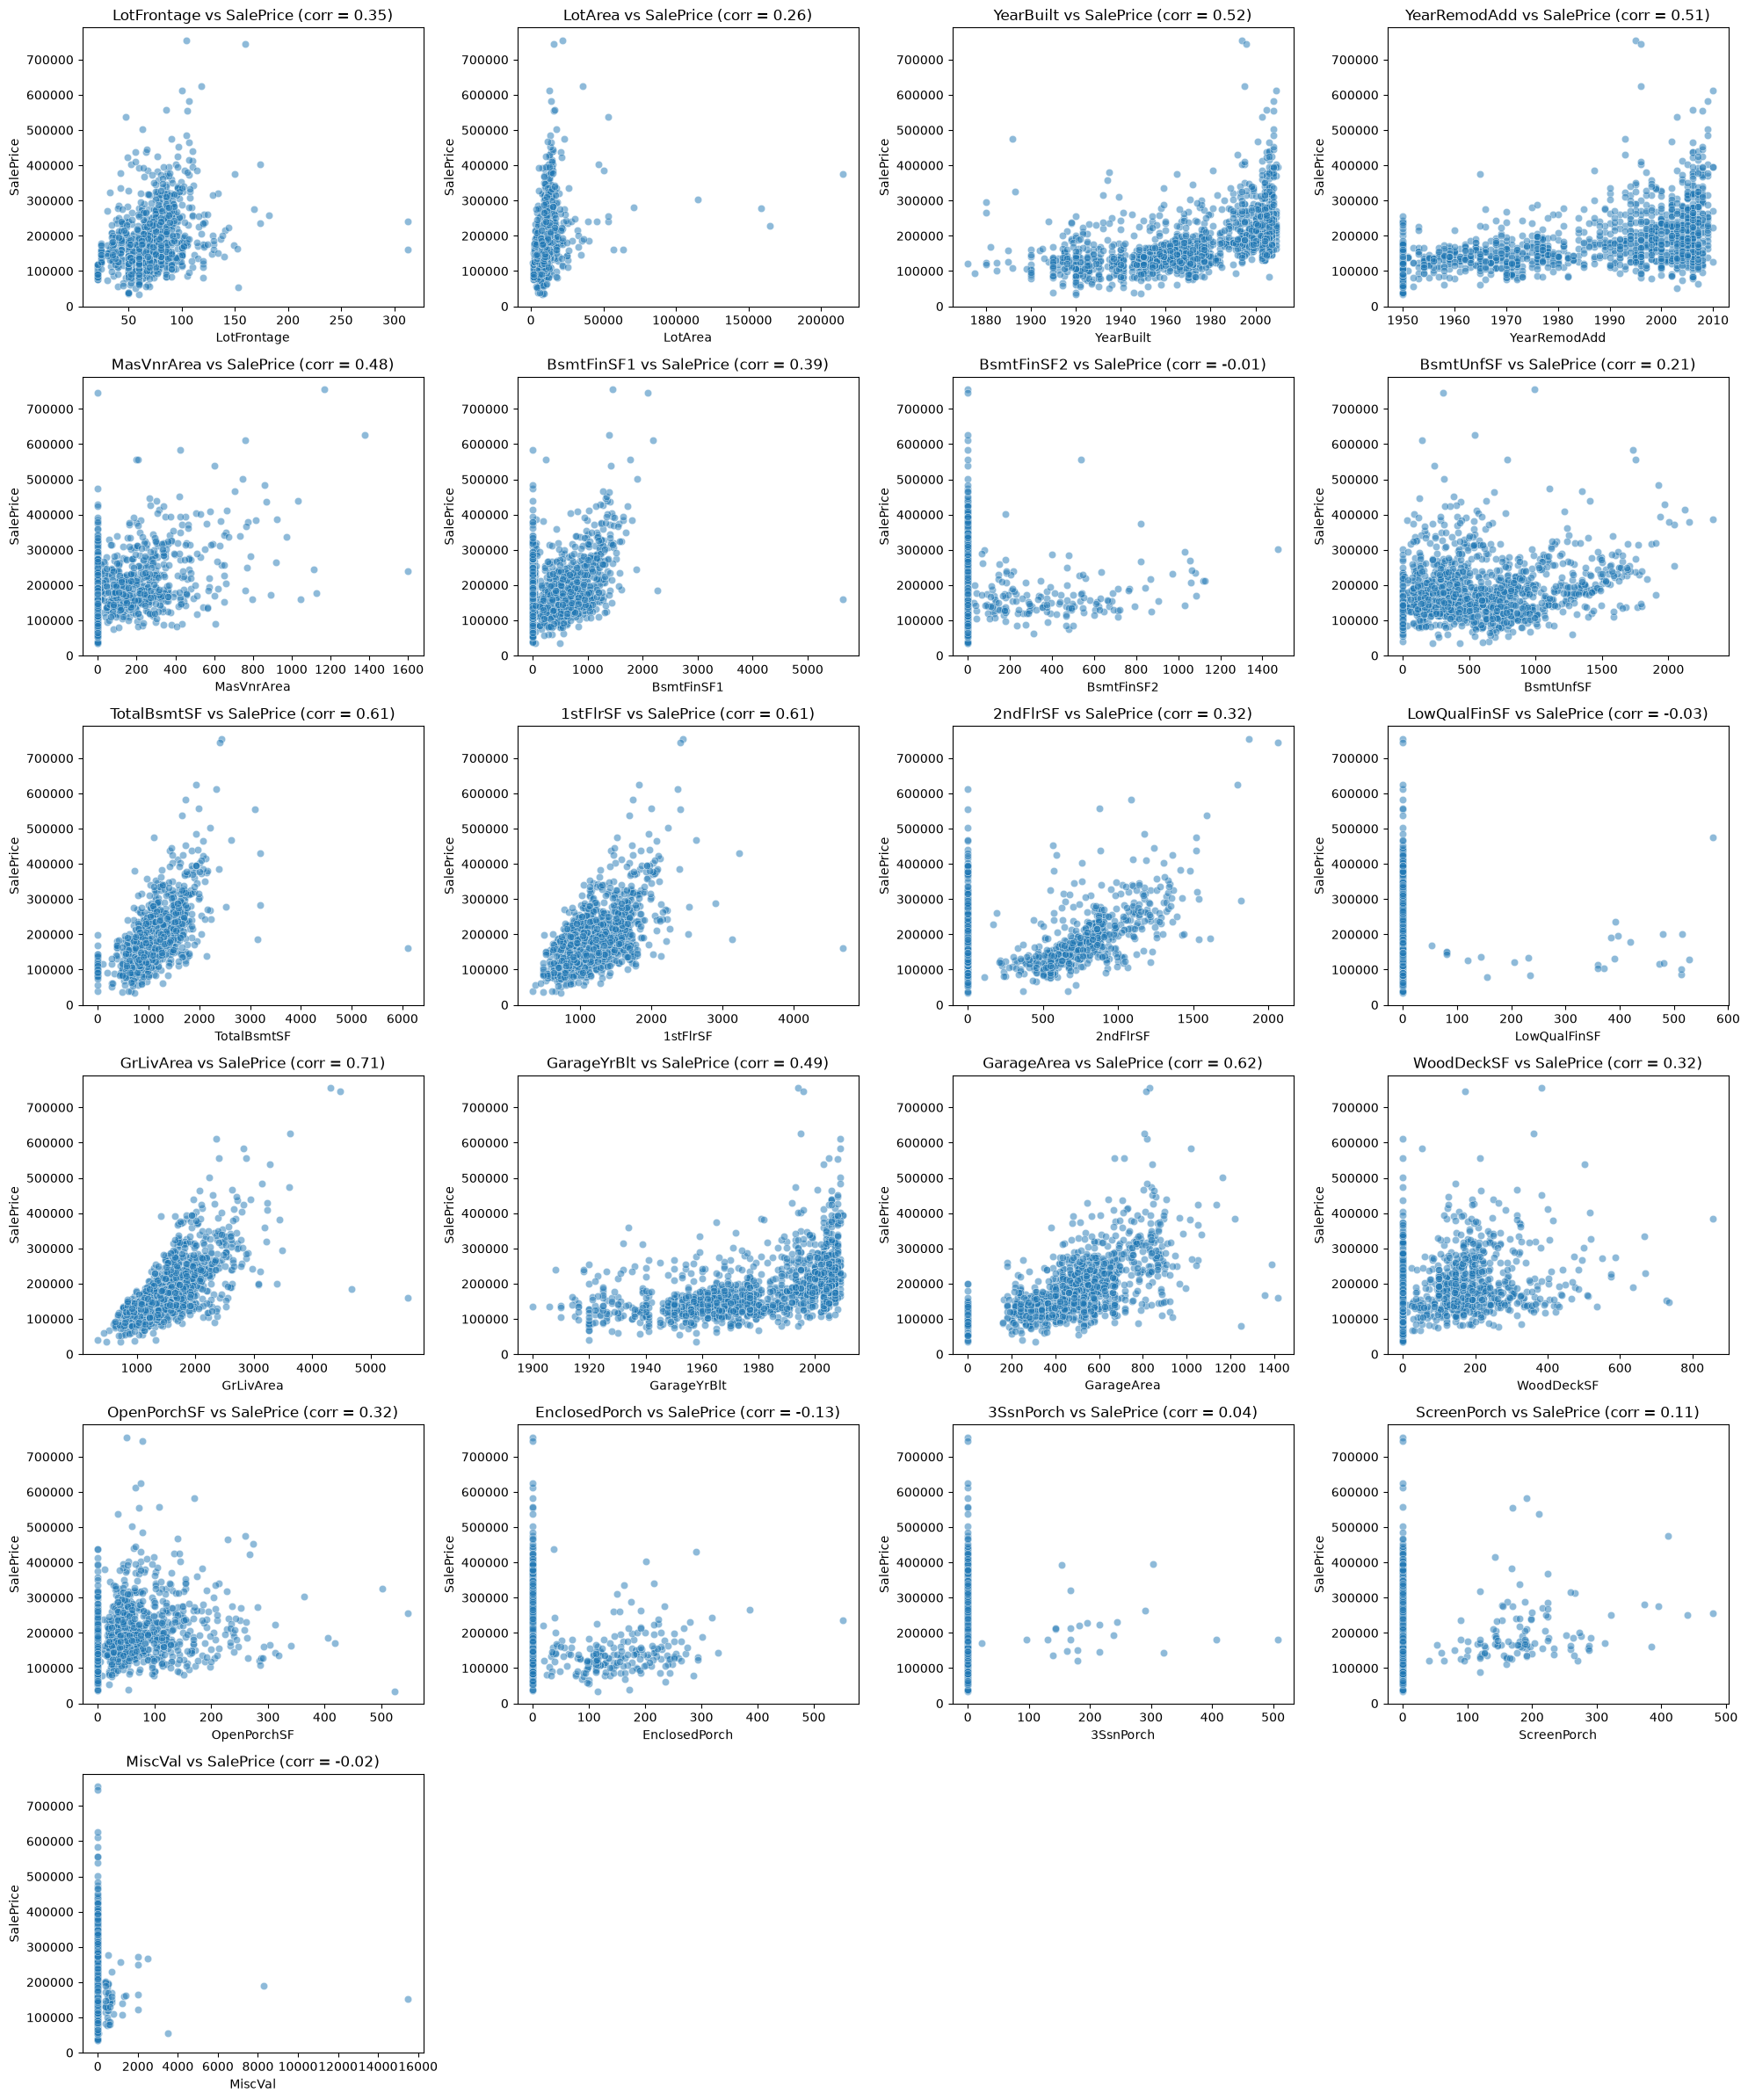

In [32]:
# Scatter plot de cada variable continua contra la variable target
N_COLS = 4
n_filas = int(np.ceil(len(continuas) / N_COLS))

fig, axes = plt.subplots(n_filas, N_COLS, figsize=(5 * N_COLS, 4 * n_filas))
axes = axes.flatten()

for ax, variable in zip(axes, continuas):
    correlacion = train[variable].corr(train[TARGET])
    sns.scatterplot(data=train, x=variable, y=TARGET, alpha=0.5, ax=ax)
    ax.set_title(f"{variable} vs {TARGET} (corr = {correlacion:.2f})")

# Ocultar los ejes sobrantes de la cuadrícula
for ax in axes[len(continuas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [33]:
# Correlación de cada variable continua con la variable target, de mayor a menor
correlaciones = (
    train[continuas]
    .corrwith(train[TARGET])
    .sort_values(ascending=False)
    .rename("correlacion")
    .rename_axis("variable")
    .reset_index()
)

correlaciones

,variable,correlacion
0,GrLivArea,0.708624
1,GarageArea,0.623431
2,TotalBsmtSF,0.613581
3,1stFlrSF,0.605852
4,YearBuilt,0.522897
5,YearRemodAdd,0.507101
6,GarageYrBlt,0.486362
7,MasVnrArea,0.477493
8,BsmtFinSF1,0.386420
9,LotFrontage,0.351799


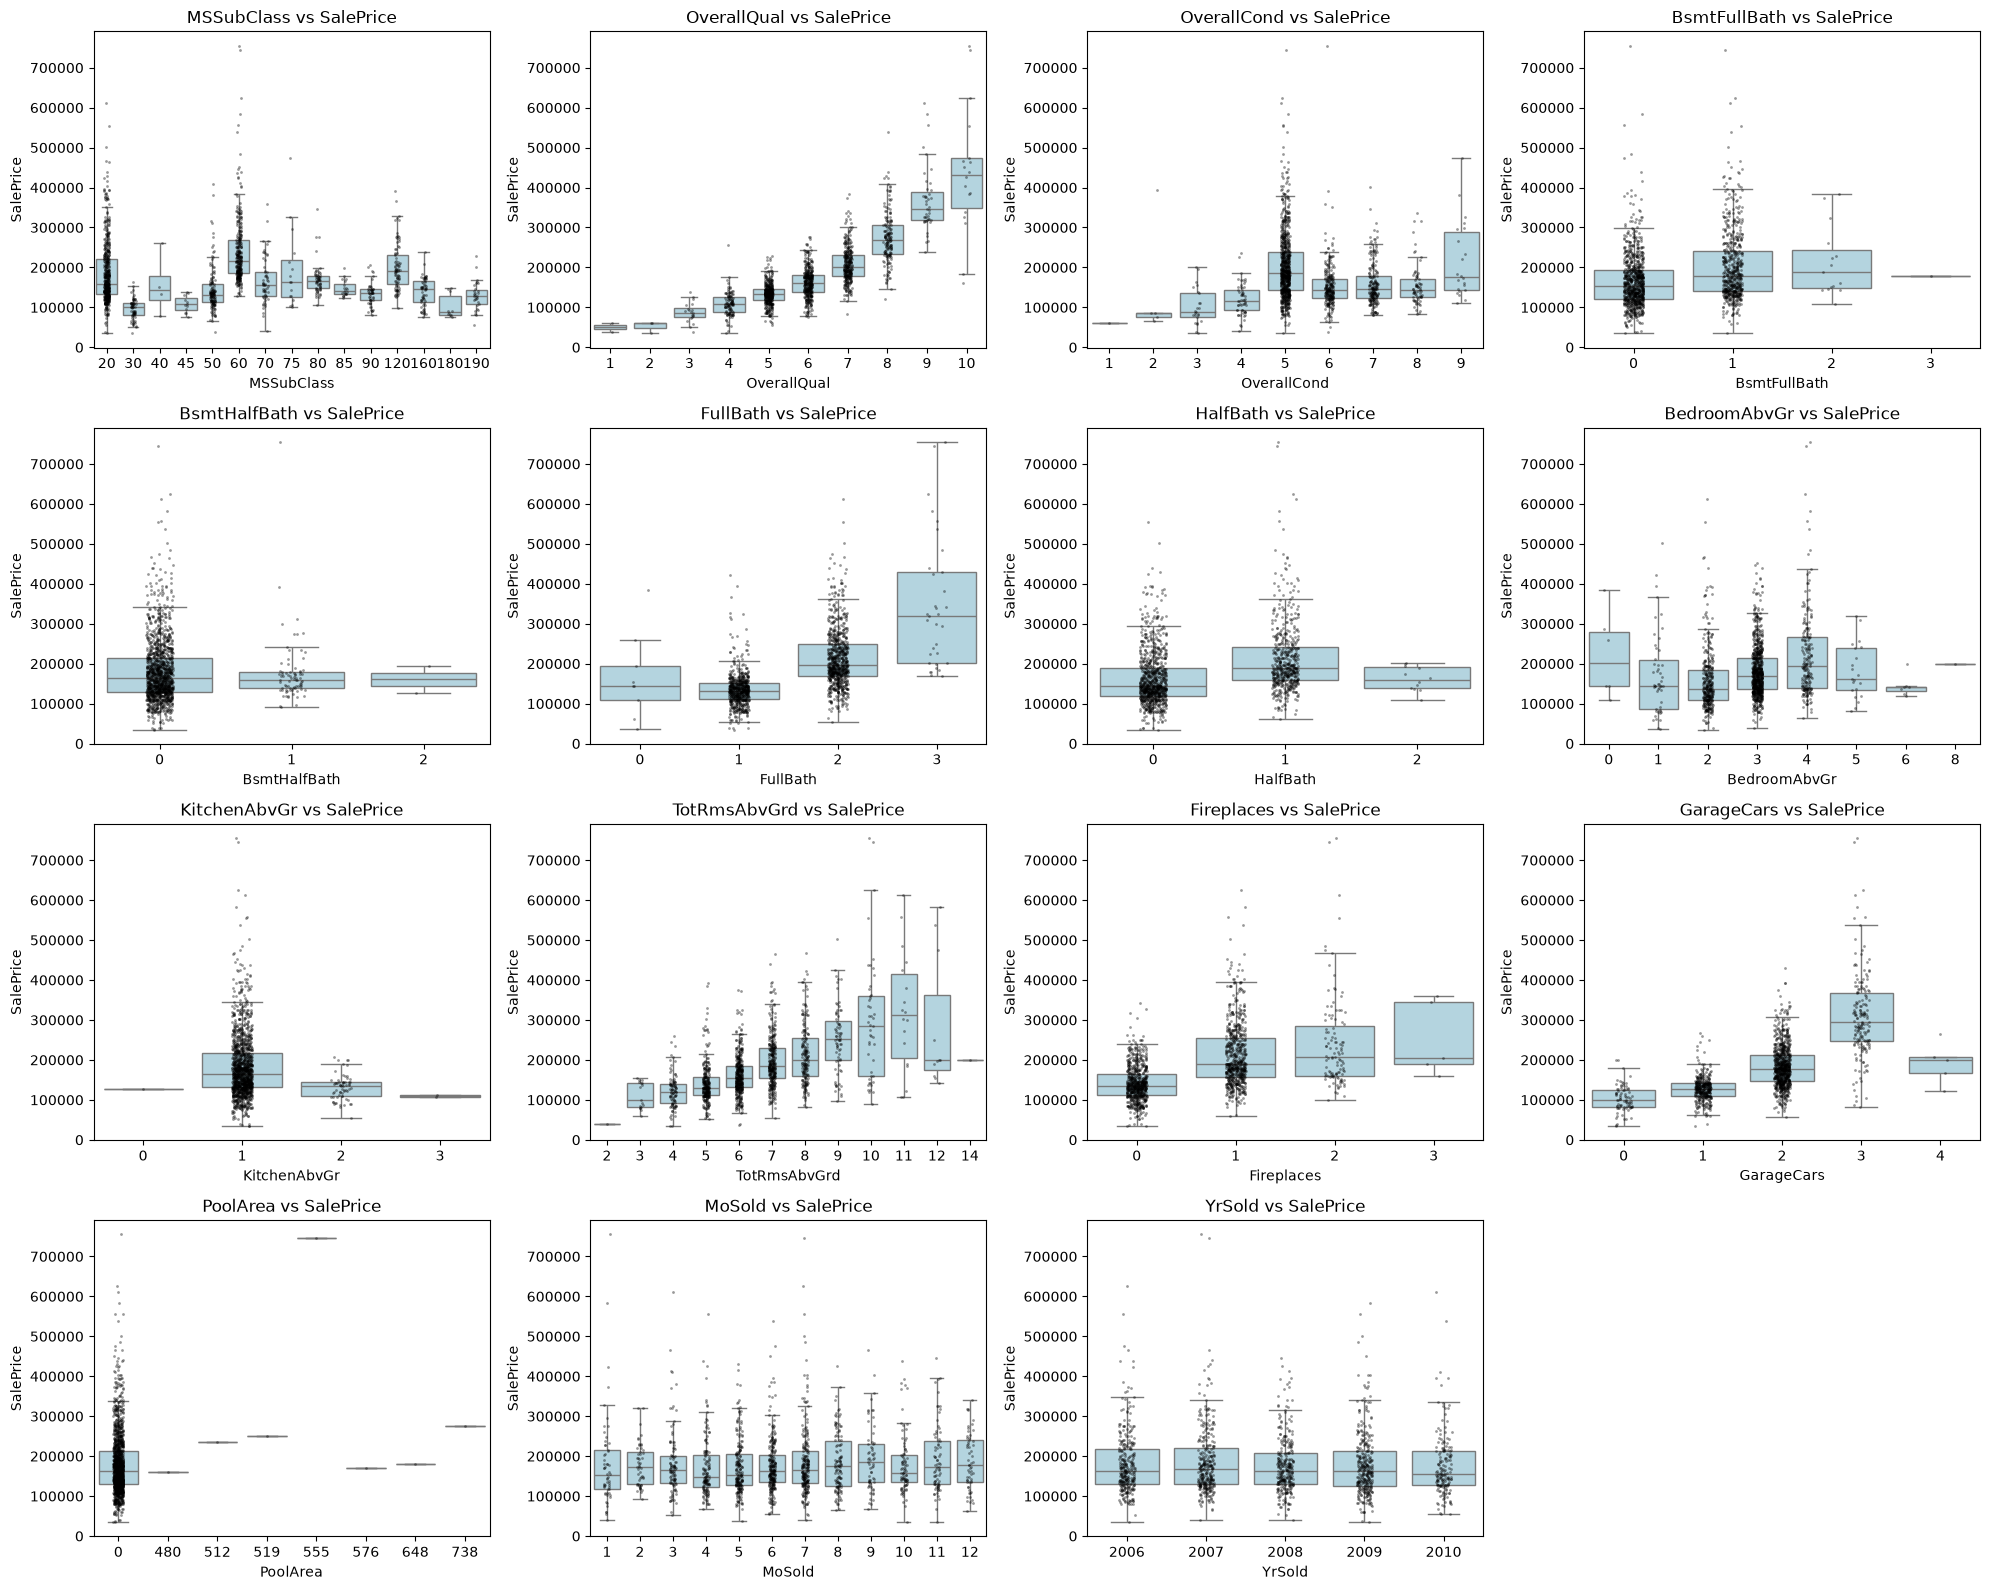

In [34]:
# Boxplot de cada variable discreta contra la variable target, con los puntos superpuestos
N_COLS = 4
n_filas = int(np.ceil(len(discretas) / N_COLS))

fig, axes = plt.subplots(n_filas, N_COLS, figsize=(5 * N_COLS, 4 * n_filas))
axes = axes.flatten()

for ax, variable in zip(axes, discretas):
    sns.boxplot(data=train, x=variable, y=TARGET, showfliers=False, color="lightblue", ax=ax)
    sns.stripplot(data=train, x=variable, y=TARGET, color="black", size=2, alpha=0.4, ax=ax)
    ax.set_title(f"{variable} vs {TARGET}")

# Ocultar los ejes sobrantes de la cuadrícula
for ax in axes[len(discretas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## Relación de las variables categóricas con SalePrice

Para medir la relación se usa la **razón de correlación** (η, *eta*), que va de 0 (las categorías no explican nada del target) a 1 (el target queda determinado por la categoría):

$$\eta = \sqrt{\frac{\sum_i n_i (\bar{y}_i - \bar{y})^2}{\sum_j (y_j - \bar{y})^2}}$$

donde $n_i$ y $\bar{y}_i$ son el número de casas y la media de SalePrice en la categoría $i$, y $\bar{y}$ es la media global.

In [35]:
def razon_correlacion(categorias, valores):
    """Razón de correlación (eta) entre una variable categórica y una numérica."""
    media_global = valores.mean()
    grupos = valores.groupby(categorias)
    varianza_entre_grupos = (grupos.count() * (grupos.mean() - media_global) ** 2).sum()
    varianza_total = ((valores - media_global) ** 2).sum()
    return np.sqrt(varianza_entre_grupos / varianza_total)


# Variables categóricas; los valores faltantes se tratan como una categoría más
categoricas = train.select_dtypes(exclude="number").columns.tolist()
VALOR_FALTANTE = "Sin dato"

print(f"categoricas ({len(categoricas)}): {categoricas}")

categoricas (43): ['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


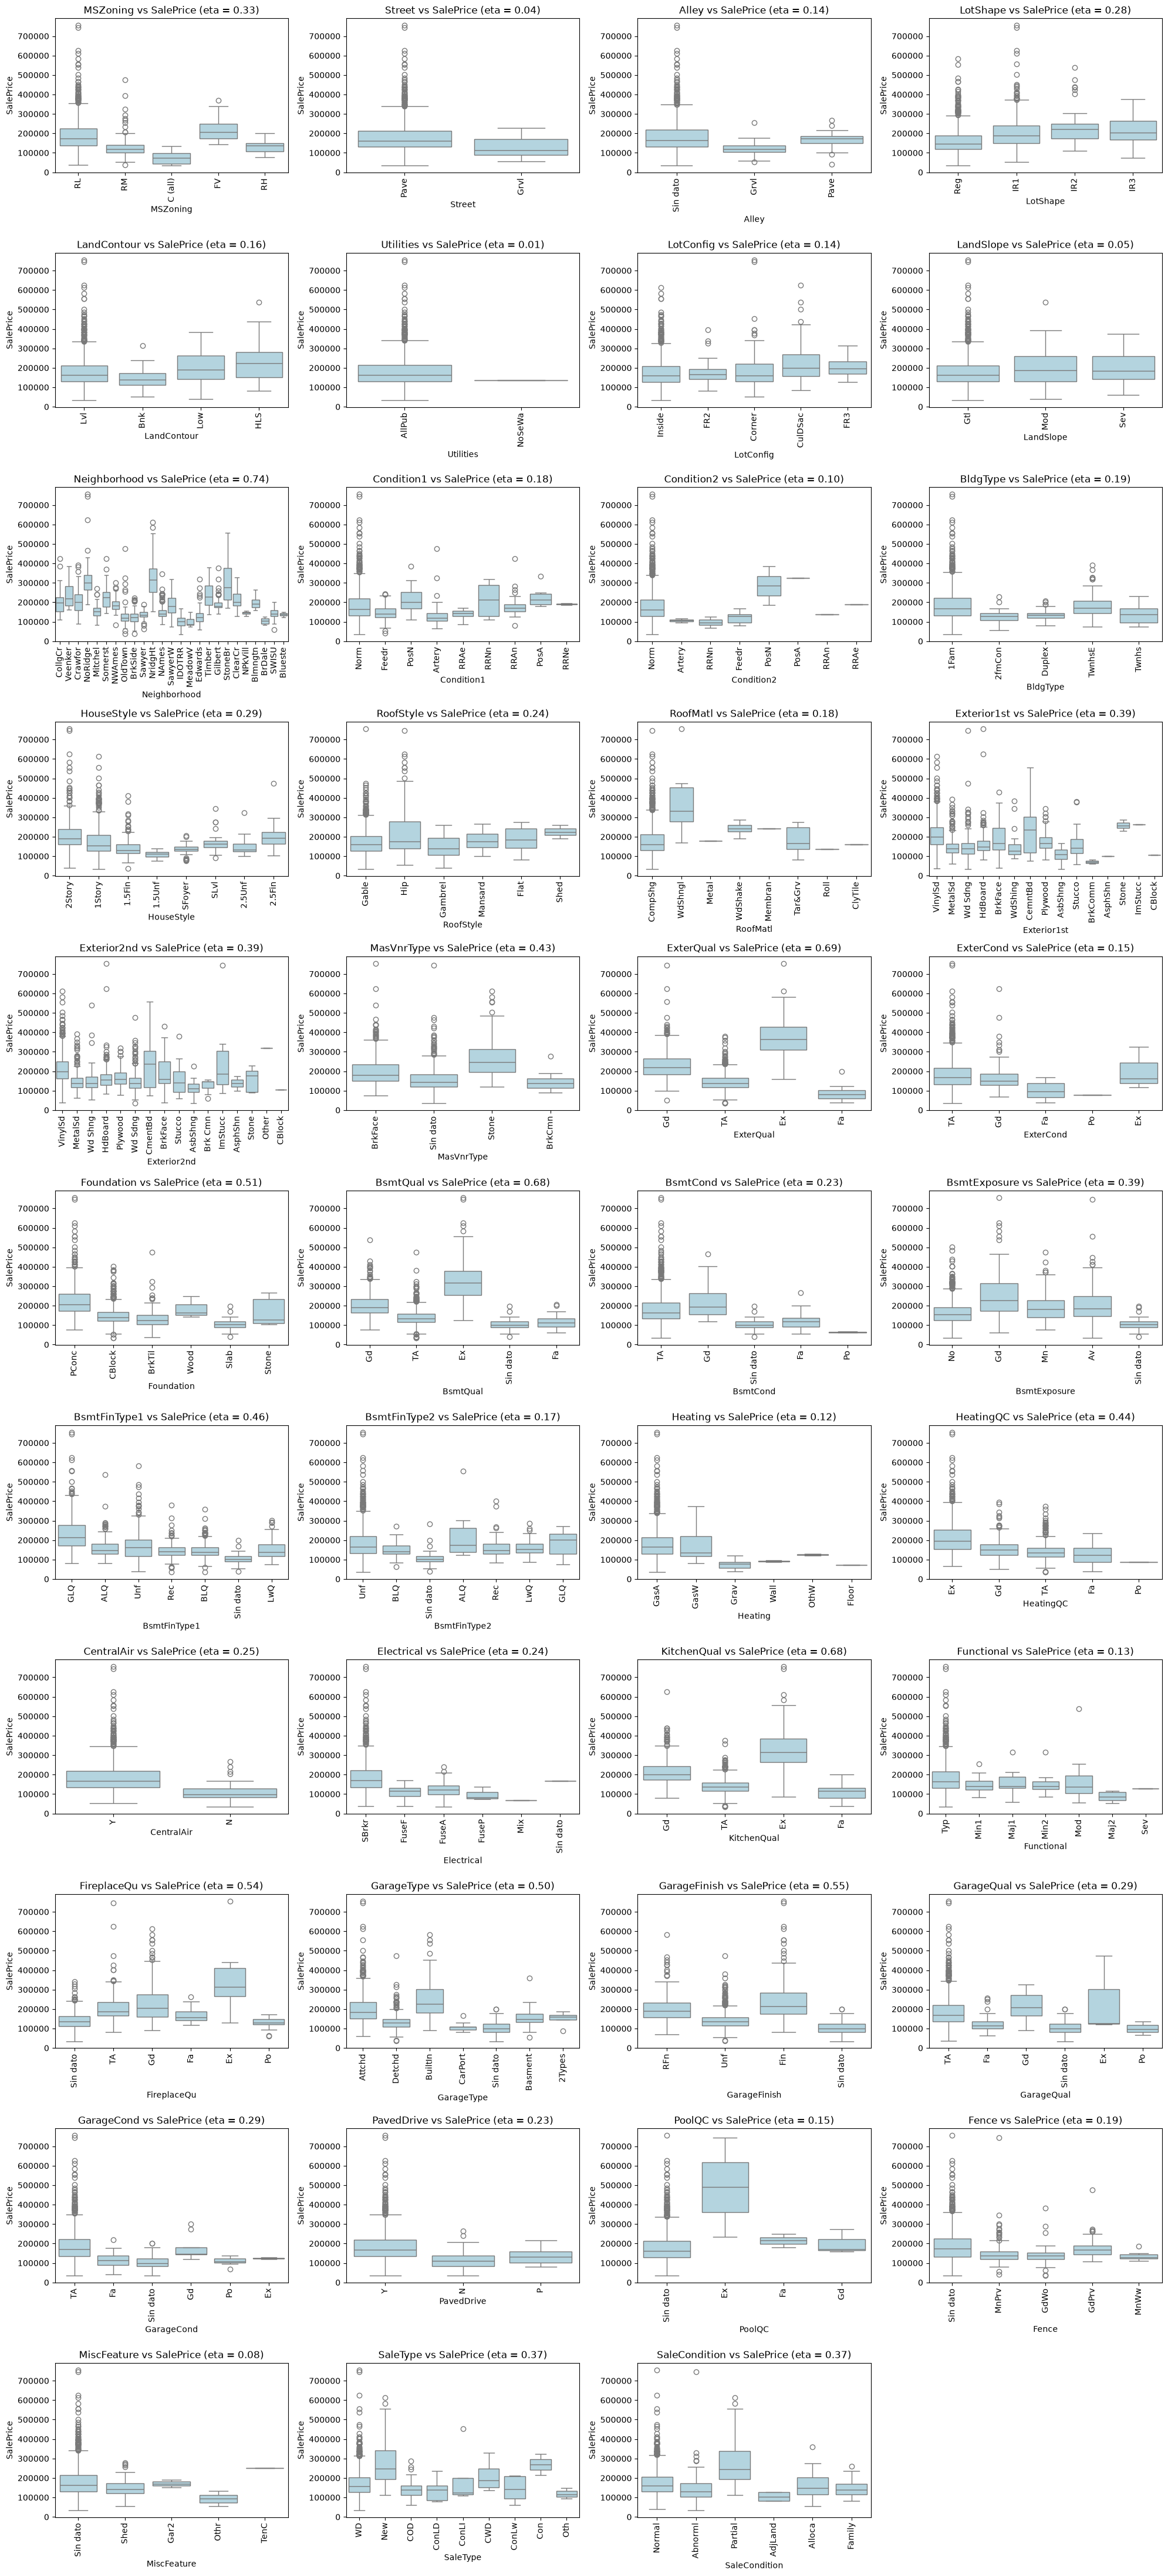

In [36]:
# Boxplot de cada variable categórica contra la variable target
N_COLS = 4
n_filas = int(np.ceil(len(categoricas) / N_COLS))

fig, axes = plt.subplots(n_filas, N_COLS, figsize=(5 * N_COLS, 4 * n_filas))
axes = axes.flatten()

for ax, variable in zip(axes, categoricas):
    categorias = train[variable].fillna(VALOR_FALTANTE)
    eta = razon_correlacion(categorias, train[TARGET])
    sns.boxplot(x=categorias, y=train[TARGET], color="lightblue", ax=ax)
    ax.set_title(f"{variable} vs {TARGET} (eta = {eta:.2f})")
    ax.tick_params(axis="x", rotation=90)

# Ocultar los ejes sobrantes de la cuadrícula
for ax in axes[len(categoricas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## Selección de features

Se eligen las 10 mejores variables de cada grupo según su métrica de relación con SalePrice:

- **Continuas:** valor absoluto de la correlación de Pearson.
- **Discretas:** razón de correlación (η), porque se analizan como grupos (boxplots).
- **Categóricas:** razón de correlación (η).

Para evitar la fuga de datos, las métricas se calculan solo con el 80% de entrenamiento, usando la misma división train / validación (`test_size = 0.2`, `random_state = 42`) que el notebook de preprocesamiento. Así, el set de validación no influye en qué variables se eligen.

In [ ]:
# Misma división que el notebook de preprocesamiento; la selección usa solo la parte de entrenamiento
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.2
RANDOM_STATE = 42

train_seleccion, _ = train_test_split(train, test_size=TEST_SIZE, random_state=RANDOM_STATE)

print(f"train_seleccion: {train_seleccion.shape}")

In [ ]:
TOP_N = 10

top_continuas = (
    train_seleccion[continuas]
    .corrwith(train_seleccion[TARGET])
    .abs()
    .sort_values(ascending=False)
    .head(TOP_N)
)
top_discretas = (
    pd.Series(
        {
            var: razon_correlacion(train_seleccion[var], train_seleccion[TARGET])
            for var in discretas
        }
    )
    .sort_values(ascending=False)
    .head(TOP_N)
)
top_categoricas = (
    pd.Series(
        {
            var: razon_correlacion(
                train_seleccion[var].fillna(VALOR_FALTANTE), train_seleccion[TARGET]
            )
            for var in categoricas
        }
    )
    .sort_values(ascending=False)
    .head(TOP_N)
)

modelo_features = (
    top_continuas.index.tolist() + top_discretas.index.tolist() + top_categoricas.index.tolist()
)

print(f"continuas: {top_continuas.index.tolist()}")
print(f"discretas: {top_discretas.index.tolist()}")
print(f"categoricas: {top_categoricas.index.tolist()}")
print(f"modelo_features ({len(modelo_features)}): {modelo_features}")

In [ ]:
# Guardar las features seleccionadas en el archivo de configuración del pipeline,
# conservando el resto de la configuración si el archivo ya existe
import yaml

CONFIG_FILE = Path(os.getenv("PIPELINE_CONFIG", "../pipeline_config.yaml"))

config = {}
if CONFIG_FILE.exists():
    with open(CONFIG_FILE, encoding="utf-8") as archivo:
        config = yaml.safe_load(archivo) or {}

config["MODEL_FEATURES"] = modelo_features

with open(CONFIG_FILE, "w", encoding="utf-8") as archivo:
    yaml.safe_dump(config, archivo, sort_keys=False, allow_unicode=True)

print(f"Configuración guardada en: {CONFIG_FILE.resolve()}")